In [15]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Ensure project root is in path
project_root = Path.cwd().parent if "__file__" not in globals() else Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from sqlalchemy import create_engine
from config.settings import DATABASE_URL

# Connect and load the 283 enriched unified rows
engine = create_engine(DATABASE_URL)
df = pd.read_sql("SELECT * FROM unified_arbitrage_enriched;", engine)

print(f"Successfully loaded dataset shape: {df.shape}")

# Safely compute profit and ROI if they weren't saved in the SQL table
if 'predicted_profit_kes' not in df.columns:
    df['predicted_profit_kes'] = df['median_local_yard_price_kes'] - df['calculated_landed_cost_kes']

if 'roi_percent' not in df.columns:
    df['roi_percent'] = (df['predicted_profit_kes'] / df['calculated_landed_cost_kes']) * 100.0

# Check missing value counts in key analytical columns
key_cols = ['clean_price', 'calculated_landed_cost_kes', 'median_local_yard_price_kes', 'predicted_profit_kes', 'roi_percent']
missing_audit = df[key_cols].isnull().sum()
print("\n=== Missing Value Audit ===")
print(missing_audit)

# Quick summary of financial metrics
print("\n=== Financial Metrics Overview (KES) ===")
display(df[['calculated_landed_cost_kes', 'median_local_yard_price_kes', 'predicted_profit_kes', 'roi_percent']].describe())

# Preview first 3 rows
display(df.head(3))

Successfully loaded dataset shape: (283, 31)

=== Missing Value Audit ===
clean_price                    0
calculated_landed_cost_kes     0
median_local_yard_price_kes    0
predicted_profit_kes           0
roi_percent                    0
dtype: int64

=== Financial Metrics Overview (KES) ===


,calculated_landed_cost_kes,median_local_yard_price_kes,predicted_profit_kes,roi_percent
count,2.830000e+02,2.830000e+02,2.830000e+02,283.000000
mean,3.744030e+06,3.789724e+06,4.569460e+04,13.047923
std,3.337521e+06,3.599424e+06,3.097192e+06,66.638169
min,8.833635e+05,7.400000e+05,-1.313674e+07,-73.674744
25%,1.706344e+06,1.695000e+06,-9.434166e+05,-30.204086
50%,2.635078e+06,2.700000e+06,-9.662550e+04,-2.932946
75%,4.569971e+06,4.773800e+06,8.764684e+05,35.482702
max,2.312213e+07,2.999900e+07,1.898447e+07,448.451042


,id,listing_url,source_site,make,model,year,mileage_km,engine_cc,fuel_type,transmission,...,enriched_at,clean_price,clean_cc,clean_year,clean_fuel,calculated_landed_cost_kes,median_local_yard_price_kes,local_listing_count,predicted_profit_kes,roi_percent
0,102,https://www.beforward.jp/honda/freed/cd774314/...,beforward,HONDA,FREED,2019.0,41000.0,1500.0,Petrol,Automatic,...,2026-10-10 08:33:30.779366+00:00,14320.0,1500.0,2019.0,Petrol,4142765.92,1980000.0,1,-2162765.92,-52.205844
1,4,https://www.beforward.jp/toyota/hilux/ce798712...,beforward,TOYOTA,HILUX,2021.0,206710.0,2393.0,Diesel,Automatic,...,2026-10-10 08:33:30.779771+00:00,19130.0,2393.0,2021.0,Diesel,5552907.25,5324500.0,6,-228407.25,-4.113291
2,112,https://www.beforward.jp/nissan/note/ce551319/...,beforward,NISSAN,NOTE,2021.0,141871.0,1200.0,Hybrid(Petrol),Cvt,...,2026-10-10 08:33:30.779781+00:00,5830.0,1200.0,2021.0,Hybrid(Petrol),2019026.38,1695000.0,2,-324026.38,-16.048645


In [16]:
# Interactive scatter plot comparing import landed cost to Nairobi yard resale price
fig = px.scatter(
    df,
    x="calculated_landed_cost_kes",
    y="median_local_yard_price_kes",
    color="roi_percent",
    hover_name="model",
    hover_data=["make", "year", "local_listing_count"],
    title="KRA Landed Import Cost vs. Nairobi Yard Resale Price (Enriched Data)",
    labels={
        "calculated_landed_cost_kes": "Total Landed Cost (KES)",
        "median_local_yard_price_kes": "Local Yard Resale Price (KES)",
        "roi_percent": "ROI %"
    },
    color_continuous_scale="Tealgrn"
)

# Add break-even diagonal reference line (Y = X)
max_val = max(df['calculated_landed_cost_kes'].max(), df['median_local_yard_price_kes'].max())
fig.add_shape(
    type="line", x0=0, y0=0, x1=max_val, y1=max_val,
    line=dict(color="crimson", dash="dash"),
    name="Break-even Line"
)

fig.show()

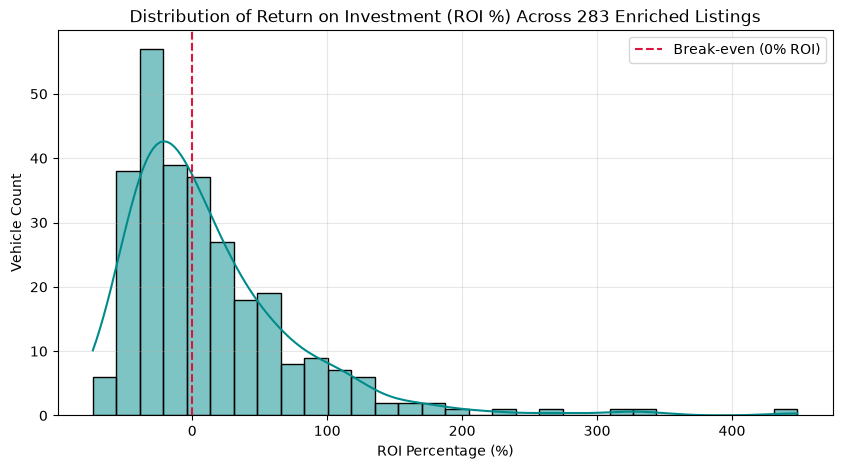

In [17]:
plt.figure(figsize=(10, 5))
sns.histplot(df['roi_percent'].dropna(), kde=True, color='darkcyan', bins=30)
plt.axvline(0, color='crimson', linestyle='--', linewidth=1.5, label='Break-even (0% ROI)')
plt.title("Distribution of Return on Investment (ROI %) Across 283 Enriched Listings")
plt.xlabel("ROI Percentage (%)")
plt.ylabel("Vehicle Count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [18]:
# Sort by highest ROI percentage
top_deals = df.sort_values(by='roi_percent', ascending=False).head(10)

print("=== Top 10 Arbitrage Opportunities by ROI % ===")
display(top_deals[[
    'make', 'model', 'year', 'clean_price', 
    'calculated_landed_cost_kes', 'median_local_yard_price_kes', 
    'predicted_profit_kes', 'roi_percent', 'local_listing_count'
]])

=== Top 10 Arbitrage Opportunities by ROI % ===


,make,model,year,clean_price,calculated_landed_cost_kes,median_local_yard_price_kes,predicted_profit_kes,roi_percent,local_listing_count
205,MITSUBISHI,PAJERO,2019.0,1800.0,1010938.00,5544500.0,4533562.00,448.451042,2
168,LAND ROVER,RANGE,2019.0,7260.0,2635078.18,11500000.0,8864921.82,336.419689,3
173,LAND ROVER,RANGE,2019.0,7670.0,2750158.21,11500000.0,8749841.79,318.157761,3
44,TOYOTA,CROWN,2019.0,2170.0,1137795.25,4200000.0,3062204.75,269.134956,1
167,LAND ROVER,RANGE,2019.0,10560.0,3561332.08,11500000.0,7938667.92,222.912880,3
170,LAND ROVER,RANGE,2019.0,11410.0,3799912.63,11500000.0,7700087.37,202.638537,3
169,LAND ROVER,RANGE,2019.0,12720.0,4167607.36,11500000.0,7332392.64,175.937703,3
163,LAND ROVER,RANGE,2022.0,40110.0,11014525.75,29999000.0,18984474.25,172.358526,1
166,LAND ROVER,RANGE,2022.0,40790.0,11191546.75,29999000.0,18807453.25,168.050527,1
171,LAND ROVER,RANGE,2019.0,13450.0,4372505.95,11500000.0,7127494.05,163.007075,3


In [19]:
# Aggregate average profit and ROI by vehicle make
make_summary = df.groupby('make').agg(
    avg_roi=('roi_percent', 'mean'),
    avg_profit=('predicted_profit_kes', 'mean'),
    listing_count=('make', 'count')
).reset_index().sort_values(by='avg_roi', ascending=False)

print("=== Average ROI and Profit by Vehicle Make ===")
display(make_summary)

=== Average ROI and Profit by Vehicle Make ===


,make,avg_roi,avg_profit,listing_count
7,MITSUBISHI,298.943021,3.282245e+06,2
4,LAND ROVER,152.835306,7.896333e+06,17
9,SUBARU,67.801917,9.895668e+05,8
0,AUDI,49.977279,5.708963e+05,2
5,LEXUS,43.083143,1.358900e+06,2
3,HONDA,14.131573,-4.098782e+04,27
2,FORD,11.714714,4.425977e+04,9
11,TOYOTA,5.696200,-7.679103e+05,131
6,MAZDA,-3.894013,-5.977567e+04,3
10,SUZUKI,-4.190466,-1.339674e+05,16
